# Build Autoencoders

### Data preprocessing

In [1]:
import numpy as np
from tensorflow.keras.datasets import mnist

In [2]:
# Load the MNIST dataset
(x_train, _), (x_test, _) = mnist.load_data()

In [3]:
# Normalize the pixel values
x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.

# Flatten the images
x_train = x_train.reshape((len(x_train), np.prod(x_train.shape[1:])))
x_test = x_test.reshape((len(x_test), np.prod(x_test.shape[1:])))

### Build the Autoencoder Model

In [4]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# Encoder
input_layer = Input(shape=(784,))
encoded = Dense(64, activation='relu')(input_layer)

# Bottleneck
bottleneck = Dense(32, activation='relu')(encoded)

# Decoder
decoded = Dense(64, activation='relu')(bottleneck)
output_layer = Dense(784, activation='sigmoid')(decoded)

# Autoencoder model
autoencoder = Model(input_layer, output_layer)

# Compile the model
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

# Summary of the model
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │        50,960 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,392 (411.69 KB)

 Trainable params: 105,392 (411.69 KB)

 Non-trainable params: 0 (0.00 B)

### Training the Autoencoder

In [5]:
autoencoder.fit(x_train, x_train,
                epochs=25,
                batch_size=256,
                shuffle=True,
                validation_data=(x_test,x_test))

Epoch 1/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.2510 - val_loss: 0.1693
Epoch 2/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1523 - val_loss: 0.1367
Epoch 3/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1301 - val_loss: 0.1228
Epoch 4/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1207 - val_loss: 0.1156
Epoch 5/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1153 - val_loss: 0.1123
Epoch 6/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1118 - val_loss: 0.1084
Epoch 7/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1085 - val_loss: 0.1057
Epoch 8/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1064 - val_loss: 0.1046
Epoch 9/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1050 - val_loss: 0.1031
Epoch 10/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1037 - val_loss: 0.1017
Epoch 11/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1023 - val_loss: 0.1000
Epoch 12/25
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step

### Evaluating the Autoencoder

In [6]:
# Predict the test data
x_test_pred = autoencoder.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


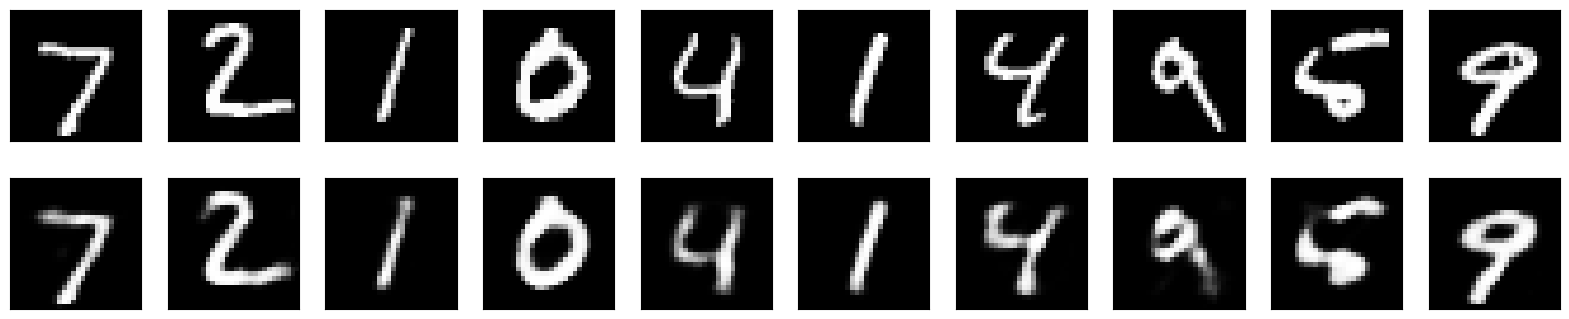

In [8]:
# visualize the results
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 4))

n=10  # number of digits to display
for i in range(n):
    # Display original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Display reconstruction
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(x_test_pred[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

### Fine-Tuning the Autoencoder

In [9]:
# Freeze all layers of the autoencoder
for layer in autoencoder.layers:
    layer.trainable = False

In [10]:
# Check trainable status of each layer
for i, layer in enumerate(autoencoder.layers):
    print(f"Layer {i}: {layer.name}, Trainable: {layer.trainable}")

Layer 0: input_layer, Trainable: False
Layer 1: dense, Trainable: False
Layer 2: dense_1, Trainable: False
Layer 3: dense_2, Trainable: False
Layer 4: dense_3, Trainable: False


In [11]:
# Unfreeze the top layers of the encoder
for layer in autoencoder.layers[-4:]:
    layer.trainable = True

# Check trainable status of each layer
for i, layer in enumerate(autoencoder.layers):
    print(f"Layer {i}: {layer.name}, Trainable: {layer.trainable}")

Layer 0: input_layer, Trainable: False
Layer 1: dense, Trainable: True
Layer 2: dense_1, Trainable: True
Layer 3: dense_2, Trainable: True
Layer 4: dense_3, Trainable: True


In [12]:
# Compile the model again
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

# Train the model again
autoencoder.fit(x_train, x_train,
                epochs=10,
                batch_size=256,
                shuffle=True,
                validation_data=(x_test,x_test))

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0935 - val_loss: 0.0919
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0930 - val_loss: 0.0917
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0928 - val_loss: 0.0914
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0926 - val_loss: 0.0916
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0924 - val_loss: 0.0913
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0923 - val_loss: 0.0912
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0922 - val_loss: 0.0910
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0920 - val_loss: 0.0909
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0919 - val_loss: 0.0909
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0918 - val_loss: 0.0906


### Denoising images with Autoencoder

In [13]:
# Add noise to the data
noise_factor = 0.5
x_train_noisy = x_train + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_train.shape)
x_test_noisy = x_test + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)
x_train_noisy = np.clip(x_train_noisy, 0., 1.)
x_test_noisy = np.clip(x_test_noisy, 0., 1.)

# Train the autoencoder with noisy data
autoencoder.fit(x_train_noisy, x_train,
                epochs=20,
                batch_size=512,
                shuffle=True,
                validation_data=(x_test_noisy, x_test))

# Denoise the test data
x_test_denoised = autoencoder.predict(x_test_noisy)

Epoch 1/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1734 - val_loss: 0.1443
Epoch 2/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1393 - val_loss: 0.1339
Epoch 3/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1322 - val_loss: 0.1292
Epoch 4/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1286 - val_loss: 0.1267
Epoch 5/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1267 - val_loss: 0.1253
Epoch 6/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1254 - val_loss: 0.1249
Epoch 7/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1246 - val_loss: 0.1235
Epoch 8/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1239 - val_loss: 0.1232
Epoch 9/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1234 - val_loss: 0.1228
Epoch 10/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1230 - val_loss: 0.1223
Epoch 11/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.1228 - val_loss: 0.1223
Epoch 12/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 9m

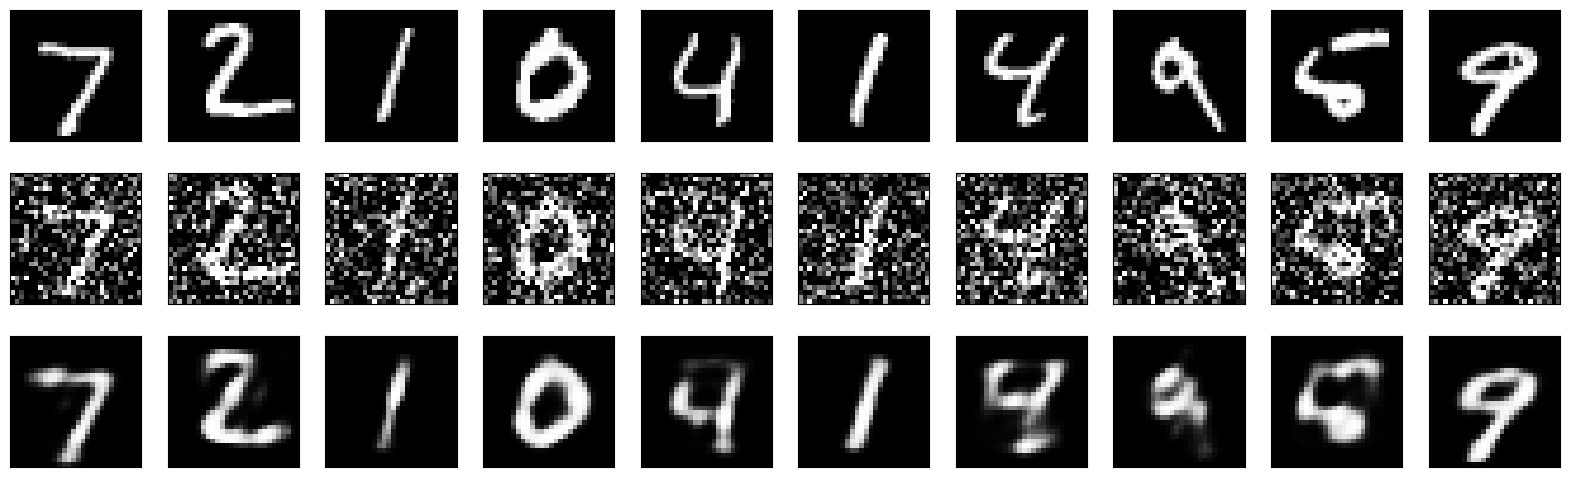

In [14]:
# Visualize the results
plt.figure(figsize=(20, 6))
n = 10  # number of digits to display
for i in range(n):
    # Display original
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Display noisy
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_noisy[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Display denoised
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(x_test_denoised[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)